In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.svm import SVC
import nltk
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tokenize import tokenize, untokenize, NUMBER, STRING, NAME, OP

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer

from sklearn.metrics import plot_confusion_matrix,classification_report

import joblib
from sklearn.pipeline import Pipeline

from sklearn.svm import LinearSVC


In [2]:
# LOAD CSV FILE

In [3]:
df = pd.read_csv("TrainingSet.csv", low_memory=False) 

In [4]:
df.head()

,ItemNumber,Description1,VendorCatno,ManuCatNo,Segment,Department,Category,SubCategory,VendorName,VendorID,12 months spend,POItemNumber,uin,ManufacturerID,ManufacturerName
0,112713,BONE SUB INNOTERE 20X10X10,221TS1,221TS1,NaN,NaN,Bone,Bone and Bone Substitutes,ARTHREX LTD,A000036,NaN,NaN,8802475,938347,ARTHREX LTD
1,103953,BONE SUBSTITUTE 3D SCFFD 20X15,321TS1,321TS1,Med/Surg,Surgery,"Arthroscopy, Implants and Instruments",Uncategorised,ARTHREX LTD,A000036,NaN,NaN,0,901314,ARTHREX LTD
2,113892,WEDGE BONE SUBSTITUTE 7MM,721TS1,721TS1,NaN,NaN,"Arthroscopy, Implants and Instruments",Trays and Accessories,ARTHREX LTD,A000036,NaN,NaN,8280931,938347,ARTHREX LTD
3,113891,WEDGE BONE SUBSTITUTE 10MM,721TS2,721TS2,NaN,NaN,Bone,Bone and Bone Substitutes,ARTHREX LTD,A000036,NaN,NaN,8808325,938347,ARTHREX LTD
4,131169,"NEEDLE W/ OBTURATOR 10GX4.5""",ABS-1001,ABS-1001,NaN,NaN,"Arthroscopy, Implants and Instruments",Trays and Accessories,ARTHREX LTD,A000036,117.72,131169.0,8279523,938347,ARTHREX LTD


In [5]:
#NOW we need to concatenate correlated to categorisation columns such as item description vendor or manufacturer

In [6]:
df['DescVendor'] = df[['Description1', 'ManufacturerName','ManuCatNo','VendorName']].astype(str).agg(' '.join, axis=1)

In [7]:
#Now we get from dataframe two columns 
#X -Independent fetures what we use to get prediction
#y - our target what we predicting

In [8]:
X = df['DescVendor']
y = df['Category']

In [9]:
X.head()

0    BONE SUB INNOTERE 20X10X10          ARTHREX LT...
1    BONE SUBSTITUTE 3D SCFFD 20X15      ARTHREX LT...
2    WEDGE BONE SUBSTITUTE 7MM           ARTHREX LT...
3    WEDGE BONE SUBSTITUTE 10MM          ARTHREX LT...
4    NEEDLE W/ OBTURATOR 10GX4.5"        ARTHREX LT...
Name: DescVendor, dtype: object

In [10]:
y.head()

0                                     Bone
1    Arthroscopy, Implants and Instruments
2    Arthroscopy, Implants and Instruments
3                                     Bone
4    Arthroscopy, Implants and Instruments
Name: Category, dtype: object

In [11]:
#Now we split all into four datasets 
#train where modle will learn how X fetures are related to our target(Category)
#test where we test accuracy of our model 

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [13]:
# Now we doing actuall model training, we used SVM( support vecor machines) for this task

In [14]:
#Good svm explanation
# https://www.youtube.com/watch?v=_YPScrckx28

In [15]:
svc = Pipeline([('tfidf',TfidfVectorizer(stop_words='english')),('svc',LinearSVC())])


In [16]:
#param_grid = {'kernel': ('linear', 'rbf','poly') , 
#              'C':[5, 10, 100],
#              'gamma': [1,0.1,0.01,0.001], 
#              'degree' : [1,2,3,4,5,6]}

In [17]:
#from sklearn.model_selection import GridSearchCV

In [18]:
#SVCpipe = Pipeline([('scale', StandardScaler()),
#                   ('SVC',LinearSVC())])

In [19]:
#param_grid = {'SVC__C':np.arange(0.01,100,10)}
#linearSVC = GridSearchCV(SVCpipe,param_grid,cv=5,return_train_score=True)

In [20]:
svc.fit(X_train,y_train)

Pipeline(steps=[('tfidf', TfidfVectorizer(stop_words='english')),
                ('svc', LinearSVC())])

In [23]:
#After training we can measure accuracy


In [24]:
#F1 = 2 * (precision * recall) / (precision + recall)
#Recall = TP / (TP + FN)
#Precision = TP / (TP + FP)


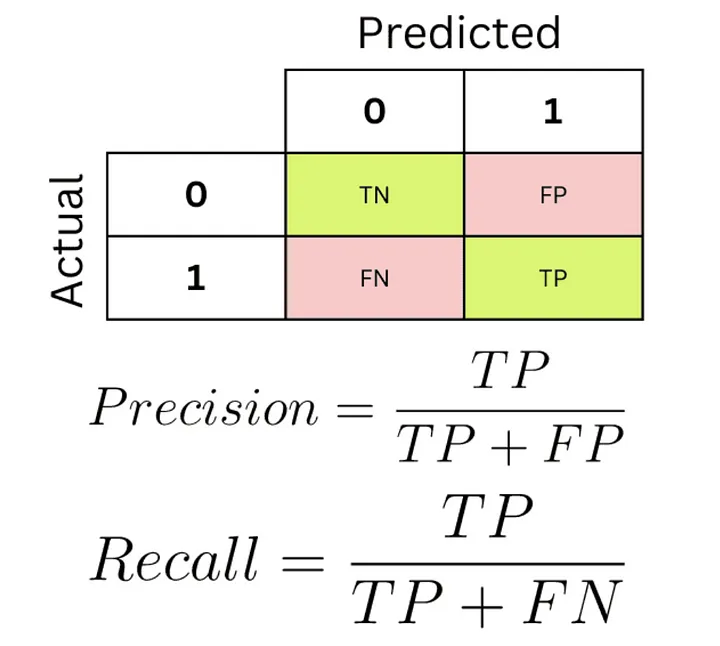

In [21]:
def report(model):
    preds = model.predict(X_test)
    print(classification_report(y_test,preds))
    #plot_confusion_matrix(model,X_test_tfidf,y_test)

In [22]:
print('SVC')
report(svc)

SVC
                                                    precision    recall  f1-score   support

                                        AAA Stents       0.00      0.00      0.00         2
          Ablation, Lasers and Ultrasound Products       1.00      0.67      0.80         3
                                    Administration       0.00      0.00      0.00         0
                    Adult Incontinence Mesh Briefs       1.00      1.00      1.00         1
        Adult Incontinence, Mesh Briefs and Liners       0.00      0.00      0.00         1
                                   Advanced Energy       0.00      0.00      0.00         3
                 Advanced Energy, Advanced Bipolar       0.67      1.00      0.80         2
                   Advanced Energy, Argon Enhanced       0.00      0.00      0.00         1
                        Advanced Energy, RF Saline       1.00      1.00      1.00         1
                       Advanced Energy, Ultrasonic       1.00      1.00    

C:\Users\tkaczmarski\.conda\envs\pracamgr1\lib\site-packages\sklearn\metrics\_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\tkaczmarski\.conda\envs\pracamgr1\lib\site-packages\sklearn\metrics\_classification.py:1248: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\tkaczmarski\.conda\envs\pracamgr1\lib\site-packages\sklearn\metrics\_classification.py:1248: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\

In [23]:
#NOW to our trained and tested model we take completly new / uncategorised data

In [24]:
df_Predict = pd.read_csv("NewData.csv", low_memory=False) 

In [25]:
df_Predict.head()

,ItemNumber,Description1,VendorCatno,ManuCatNo,Segment,Department,Category,SubCategory,VendorName,VendorID,12 months spend,POItemNumber,uin,ManufacturerID,ManufacturerName
0,139520,KIT ACP MAX PRP SYSTEM,ABS-10013,ABS-10013,NaN,NaN,NaN,NaN,ARTHREX LTD,A000036,NaN,NaN,0,0,ARTHREX LTD
1,139129,KIT ACP MAX PRP SYSTEM,ABS-10013-B,ABS-10013-B,NaN,NaN,NaN,NaN,ARTHREX LTD,A000036,990.00,139129.0,0,901314,ARTHREX LTD
2,137958,GRAFT OSTEOAUGER BONE 8MM,ABS-8000-08,ABS-8000-08,NaN,NaN,NaN,NaN,ARTHREX LTD,A000036,417.91,137958.0,0,901314,ARTHREX LTD
3,9000189,000036 HIRE OF ACJ INSTS,ACJ-01,ACJ,NaN,NaN,NaN,NaN,ARTHREX LTD,A000036,NaN,NaN,0,901314,ARTHREX LTD
4,9000254,000036 HIRE ACJ INSTS SET 4,ACJ-04,ACJ-04,NaN,NaN,NaN,NaN,ARTHREX LTD,A000036,NaN,NaN,0,901314,ARTHREX LTD


In [26]:
df_Predict['DescVendor'] = df_Predict[['Description1', 'ManufacturerName','ManuCatNo','VendorName']].astype(str).agg(' '.join, axis=1)

In [27]:
ProposedCategory1 = svc.predict(["000036 HIRE OF ANKLE DISTRACTOR     ARTHREX LTD ANKLE ARTHREX LTD"]) 
ProposedCategory1

array(['Casting, Padding, Splinting and Related Supplies'], dtype=object)

In [20]:
for i in df:
    X = df_Predict['DescVendor']
    ProposedCategory = svc.predict(X)
    ProposedCategory = pd.DataFrame(ProposedCategory, columns=['ProposedCategory'])
    df_merged = (pd.concat([X, ProposedCategory], axis=1))

In [21]:
df_merged

,DescVendor,ProposedCategory
0,KIT ACP MAX PRP SYSTEM ARTHREX LT...,"Arthroscopy, Implants and Instruments"
1,KIT ACP MAX PRP SYSTEM ARTHREX LT...,"Arthroscopy, Implants and Instruments"
2,GRAFT OSTEOAUGER BONE 8MM ARTHREX LT...,"Arthroscopy, Implants and Instruments"
3,000036 HIRE OF ACJ INSTS ARTHREX LT...,"Arthroscopy, Implants and Instruments"
4,000036 HIRE ACJ INSTS SET 4 ARTHREX LT...,Loan Kit
...,...,...
16567,CUSTOM PARTIAL PELVIC 58/64MM IMPLANTCAS...,"Instruments, Surgical, General and Specialty"
16568,BONE MODEL CUSTOM MADE PSI IMPLANTCAS...,"Instruments, Surgical, General and Specialty"
16569,BONE MODEL CUSTOM MADE PSI IMPLANTCAS...,"Instruments, Surgical, General and Specialty"
16570,CUSTOM MADE TRIAL IMPLANT PSI IMPLANTCAS...,"Instruments, Surgical, General and Specialty"


In [22]:
df_output = df_Predict.merge(df_merged, how='inner', on='DescVendor')

In [23]:
df_output.to_csv('NewData_ProposedCategories_Presentation.csv', index=False)  